# Basic CNN vs MANet on your own cat photos

Loads the best checkpoint of each model, runs a photo through both and shows the results side by side:

| original | basic CNN | MANet | where they disagree |
|---|---|---|---|

1. Put photos in `my_cats/` (jpg / png / webp / bmp), or set `IMAGE_PATH` below to one file anywhere on disk.
2. Run all cells.

Predictions are made at 256×256 (what the models were trained on) and resized back to the photo's full resolution.

In [1]:
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from manet_lib import build_model, count_params, predict_image, mask_outline, overlay

# ---- settings -------------------------------------------------------------
IMAGE_PATH = None          # e.g. r"C:\Users\me\Pictures\cat.jpg"; None = every photo in my_cats/
MY_CATS = Path("my_cats")
TTA = True                 # horizontal-flip test-time augmentation
THRESH = 0.5               # probability above which a pixel counts as cat
SAVE = True                # save each comparison figure to outputs/
# ---------------------------------------------------------------------------

CHECKPOINTS = {
    "Basic CNN": "checkpoints/basiccnn_e80_pets_best.pt",
    "MANet":     "checkpoints/manet_e80_pets_best.pt",
}
IMG_SIZE = 256
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Load the best checkpoints

In [2]:
models = {}
for name, path in CHECKPOINTS.items():
    ckpt = torch.load(path, map_location=device)
    m = build_model(ckpt["model_name"]).to(device)
    m.load_state_dict(ckpt["model"]); m.eval()
    models[name] = m
    print(f"{name:10s} {ckpt['model_name']:9s} {count_params(m) / 1e6:6.2f}M params | "
          f"best epoch {ckpt['epoch']}, val Dice {ckpt['val_dice']:.4f}")

Basic CNN  BasicCNN    0.28M params | best epoch 75, val Dice 0.8329


MANet      MANet      33.40M params | best epoch 30, val Dice 0.8992


## Compare function

In [3]:
def load_photo(path):
    # exif_transpose: phone photos are often stored sideways with a rotation tag
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")


def compare(path, save=SAVE):
    """Run one photo through both models and plot them side by side."""
    path = Path(path)
    img = load_photo(path)
    arr = np.asarray(img) / 255.0
    lw = max(2, img.width // 250)

    probs = {name: predict_image(m, img, IMG_SIZE, device=device, tta=TTA) for name, m in models.items()}
    preds = {name: p > THRESH for name, p in probs.items()}
    cnn, manet = preds["Basic CNN"], preds["MANet"]

    panel_h = 5.5
    panel_w = min(5.5, max(3.2, panel_h * img.width / img.height))  # fit portrait and landscape photos
    fig, ax = plt.subplots(1, 4, figsize=(4 * panel_w, panel_h + 0.8))
    ax[0].imshow(arr); ax[0].set_title(f"{path.name}  ({img.width}×{img.height})")
    for a, (name, pred) in zip(ax[1:3], preds.items()):
        shown = overlay(arr, pred, color=(1.0, 0.3, 0.1), alpha=0.35)
        shown[mask_outline(pred, width=lw)] = (1.0, 0.1, 0.1)
        a.imshow(shown)
        a.set_title(f"{name}: {pred.mean():.0%} of pixels = cat")

    # disagreement map: green = only MANet says cat, magenta = only CNN says cat
    diff = arr * 0.35
    diff[manet & ~cnn] = (0.1, 0.9, 0.2)
    diff[cnn & ~manet] = (0.95, 0.1, 0.85)
    agree = 2 * (cnn & manet).sum() / max(cnn.sum() + manet.sum(), 1)
    ax[3].imshow(diff)
    ax[3].set_title(f"Disagreement (agreement Dice {agree:.2f})\n"
                    "green = only MANet, magenta = only CNN", fontsize=10)
    for a in ax: a.axis("off")
    fig.suptitle(f"Basic CNN vs MANet{' (flip TTA)' if TTA else ''}, threshold {THRESH}", y=1.0)
    plt.tight_layout()
    if save:
        fig.savefig(OUT_DIR / f"04_compare_{path.stem}.png", dpi=80, bbox_inches="tight")
    plt.show()
    return {"photo": path.name, "CNN cat %": round(100 * cnn.mean(), 1),
            "MANet cat %": round(100 * manet.mean(), 1), "agreement Dice": round(float(agree), 3)}

## Run it

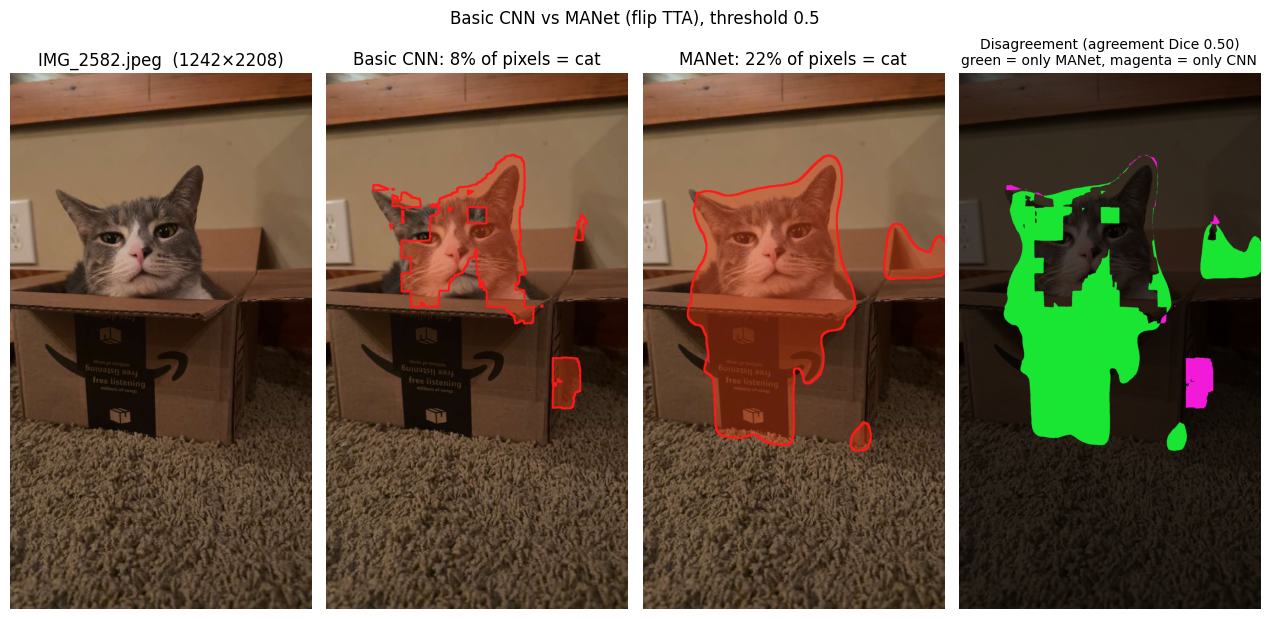

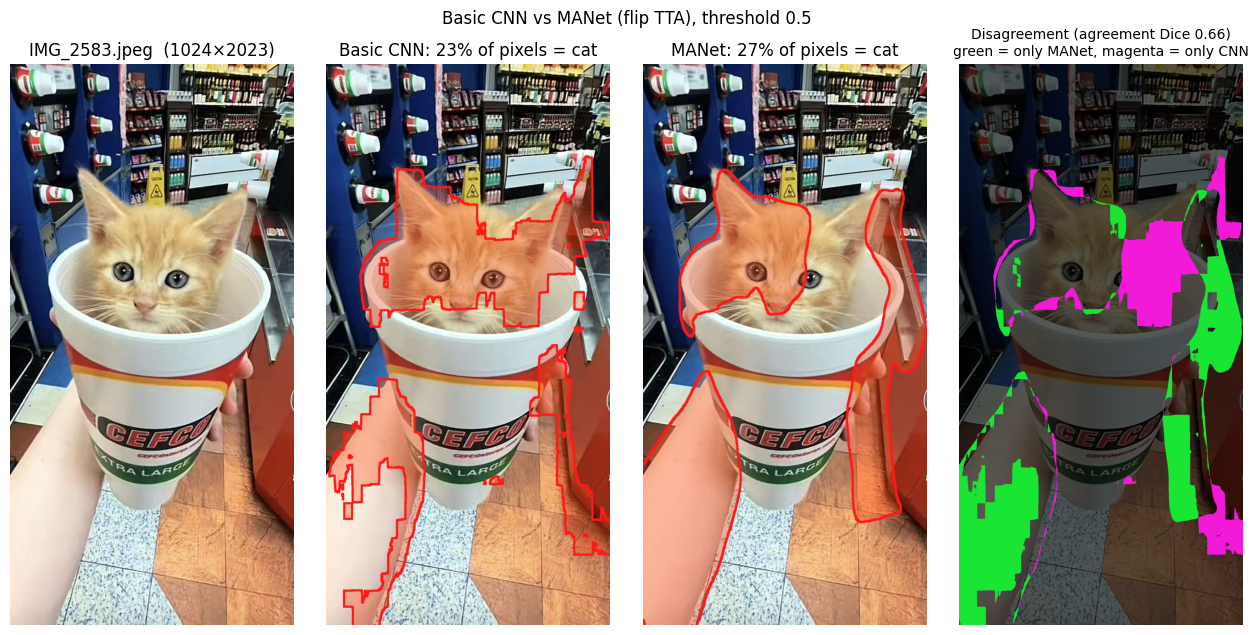

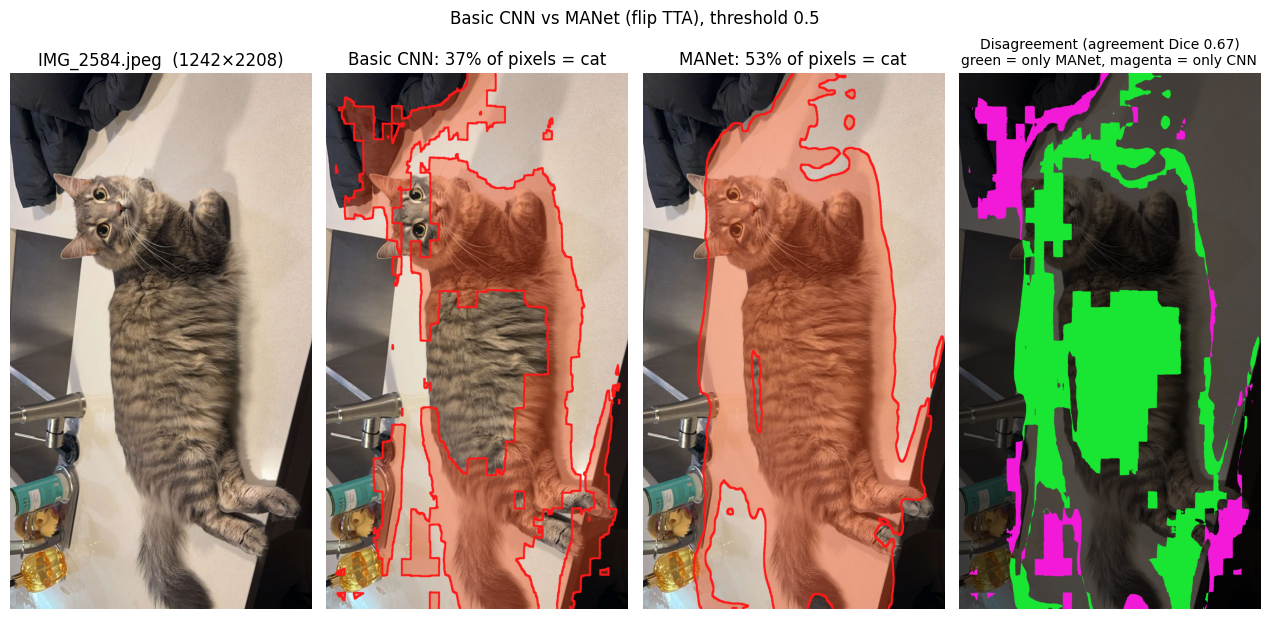

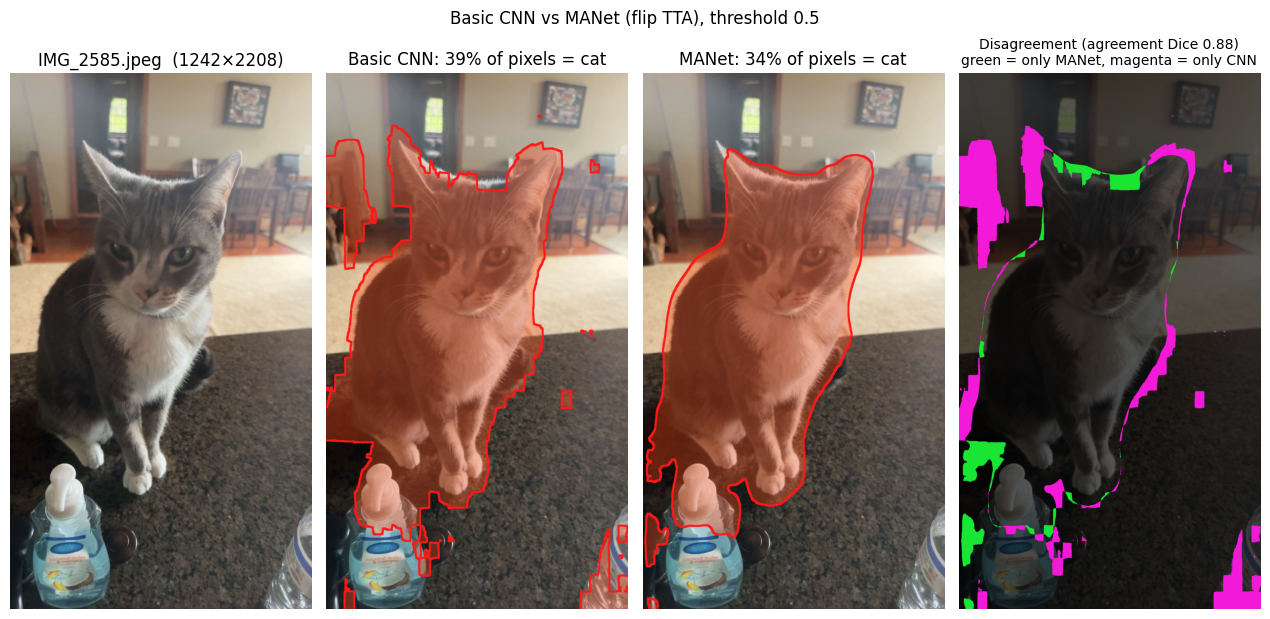

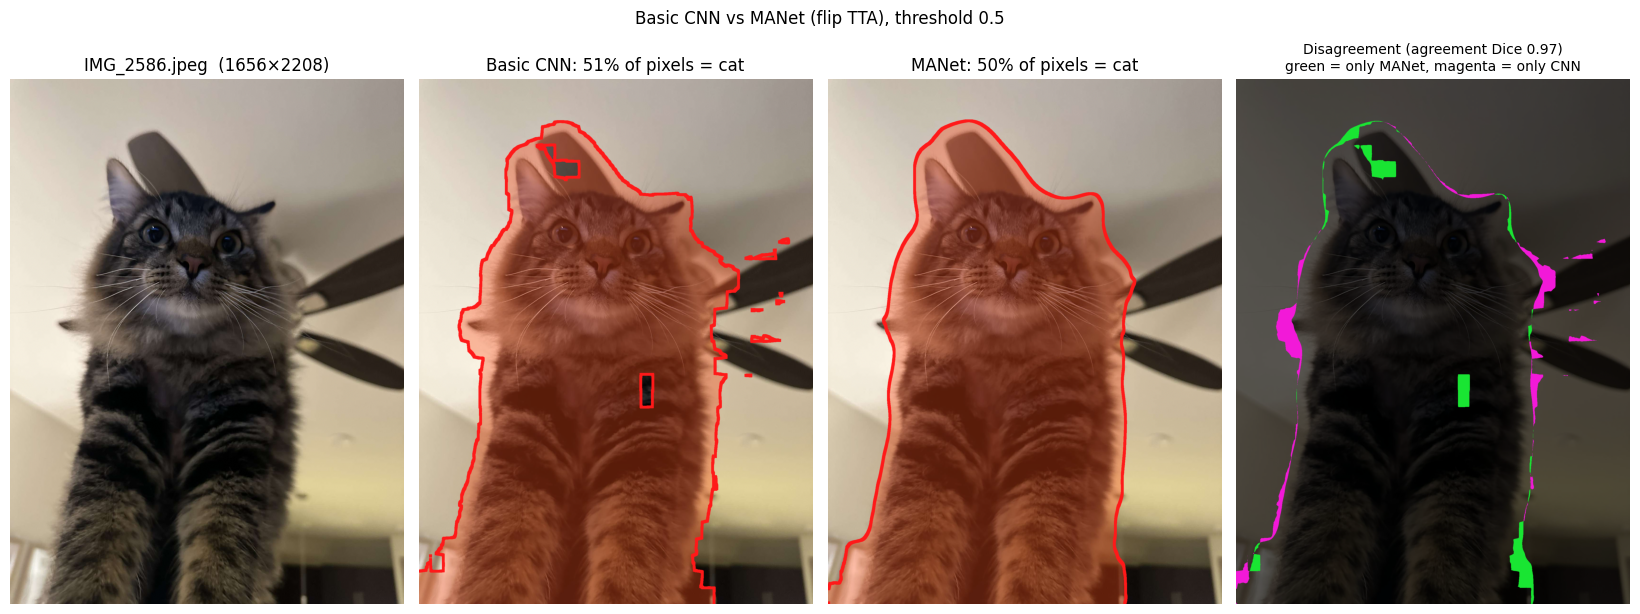

In [4]:
exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
photos = [Path(IMAGE_PATH)] if IMAGE_PATH else sorted(p for p in MY_CATS.glob("*") if p.suffix.lower() in exts)
if not photos:
    print(f"No photos found. Put some in {MY_CATS.resolve()} or set IMAGE_PATH.")

summary = [compare(p) for p in photos]

In [5]:
import pandas as pd
pd.DataFrame(summary)

,photo,CNN cat %,MANet cat %,agreement Dice
0,IMG_2582.jpeg,8.4,21.5,0.501
1,IMG_2583.jpeg,22.7,27.2,0.663
2,IMG_2584.jpeg,36.6,52.9,0.672
3,IMG_2585.jpeg,38.9,34.2,0.879
4,IMG_2586.jpeg,50.5,50.3,0.974


**Reading the results.** Neither model has a ground-truth mask for your photos, so there is no score here;
the disagreement panel shows *where* the two models differ. On the test set MANet was right more often
(cat Dice 0.903 vs 0.840 with flip TTA), so green regions are usually MANet catching fur/ears/tails the CNN
missed, and magenta regions are usually CNN false positives on background.